# Projeto Habitação MCMV: Carregamento das bases

**Objetivo:** carregar e conferir as bases abertas do Programa Minha Casa, Minha Vida (MCMV) e do FNHIS, antes da limpeza e da análise.

**Fonte dos dados:** Ministério das Cidades, Secretaria Nacional de Habitação (SNH). Página de bases: https://www.gov.br/cidades/pt-br/acesso-a-informacao/acoes-e-programas/habitacao/programa-minha-casa-minha-vida/bases-de-dados-do-programa-minha-casa-minha-vida

**Dicionário de dados:** *Dicionários de Dados SNH*, versão 2.4, de 09/10/2025 (arquivo em `documentacao/`).

## 1. Ambiente virtual

Ambiente virtual isola as bibliotecas do projeto. A pasta `.venv/` não vai para o GitHub (está no `.gitignore`).

**Criar e ativar (Windows, na raiz do projeto):**

```bash
python -m venv .venv
.venv\Scripts\activate
```

**Instalar as bibliotecas:**

```bash
pip install pandas numpy matplotlib openpyxl xlrd python-calamine jupyter ipykernel
```

**Gerar o `requirements.txt`:**

```bash
pip freeze > requirements.txt
```

Para recriar o ambiente em outra máquina: `pip install -r requirements.txt`.

**Kernel do notebook:** o notebook precisa usar o interpretador `mcmv\.venv\Scripts\python.exe`, e não o Python do Anaconda. A célula abaixo confirma qual está em uso.

## 2. Identificação do kernel

In [56]:
import sys
print(sys.executable)

c:\Users\hlcor\Documents\2026\Cursos\dscience\mcmv\.venv\Scripts\python.exe


## 3. Importações

- **`pathlib.Path`**: monta caminhos de arquivo de forma independente do sistema operacional (barras `\` no Windows e `/` no Linux/macOS).
- **`pandas` (`pd`)**: lê, manipula e confere tabelas. É a biblioteca central da análise.
- **`matplotlib.pyplot` (`plt`)**: gráficos exploratórios, usados nas próximas etapas.

Motores de leitura usados pelo `pandas`:

- **`openpyxl`**: leitura de `.xlsx`.
- **`xlrd`**: leitura de `.xls` no formato antigo.
- **`python-calamine`**: motor `engine="calamine"`, usado para o arquivo `.xls` do FNHIS.

In [57]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

## 4. Carregamento das bases

Os arquivos ficam em `dados/brutos/` e nunca são alterados. Os caminhos são relativos ao notebook, que está em `notebooks/`.

**Ajustes de leitura:**

- **Encoding `utf-8`**: confirmado para os CSVs. Sem ele, os acentos dos nomes de municípios aparecem quebrados (ex.: `GoiÃ¢nia`).
- **Separador `;` e decimal `,`**: padrão das bases brasileiras.
- **`dtype` para identificadores**: códigos IBGE, códigos de operação, CNPJ e CEP são lidos como texto, para não perder zeros à esquerda nem usar notação científica.
- **`.xls` do FNHIS**: lido com `engine="calamine"`.

Arquivo `mcmv_financ_analitico_20260724.csv` está fora do carregamento por ter mais de 1 GB.

In [58]:
# Caminho do arquivo, relativo ao notebook (que está em notebooks/)
caminho = Path("..") / "dados" / "brutos" / "mcmv_subsidiado_20260630.csv"

# Colunas de identificadores lidas como texto, para não perder zeros nem usar notação científica
colunas_texto = ["cod_ibge", "cod_operacao", "txt_cnpj_construtora_entidade", "txt_cep"]

df_sub = pd.read_csv(
    caminho,
    sep=";",
    encoding="utf-8",
    decimal=",",
    thousands=".",          # remove o separador de milhar antes de converter
    dtype={c: str for c in colunas_texto},
)

# Confere os nomes reais das colunas, incluindo a de situação do empreendimento
print(df_sub.columns.tolist())

['data_referencia', 'cod_ibge', 'txt_nome_municipio', 'txt_sigla_uf', 'txt_regiao', 'dt_assinatura', 'cod_operacao', 'txt_nome_empreendimento', 'txt_nome_agente_financeiro', 'txt_modalidade', 'txt_situacao_empreendimento', 'qtd_uh', 'qtd_uh_entregues', 'qtd_uh_vigentes', 'qtd_uh_distratadas', 'val_contratado_total', 'val_desembolsado', 'txt_cnpj_construtora_entidade', 'txt_nome_construtora_entidade', 'txt_endereco', 'txt_cep']


In [ ]:
# Cria uma tabela com a posição e o nome de cada coluna
colunas = pd.DataFrame({
    "nº": range(1, len(df_sub.columns) + 1),
    "coluna": df_sub.columns,
})

# Exibe a tabela sem o índice padrão do pandas
display(colunas.set_index("nº"))

,coluna
nº,
1,data_referencia
2,cod_ibge
3,txt_nome_municipio
4,txt_sigla_uf
5,txt_regiao
6,dt_assinatura
7,cod_operacao
8,txt_nome_empreendimento
9,txt_nome_agente_financeiro


In [60]:
# Imprime cada coluna em uma linha, com a posição à esquerda
for i, col in enumerate(df_sub.columns, start=1):
    print(f"{i:>2}. {col}")

 1. data_referencia
 2. cod_ibge
 3. txt_nome_municipio
 4. txt_sigla_uf
 5. txt_regiao
 6. dt_assinatura
 7. cod_operacao
 8. txt_nome_empreendimento
 9. txt_nome_agente_financeiro
10. txt_modalidade
11. txt_situacao_empreendimento
12. qtd_uh
13. qtd_uh_entregues
14. qtd_uh_vigentes
15. qtd_uh_distratadas
16. val_contratado_total
17. val_desembolsado
18. txt_cnpj_construtora_entidade
19. txt_nome_construtora_entidade
20. txt_endereco
21. txt_cep


### 4.1 Conferência da tabela MCMV-Subsidiado

Nesta etapa, comparamos as colunas lidas com o dicionário de dados (página 2 do PDF). As 21 colunas batem com o dicionário. Os nomes `txt_cnpj_construtora_entidade` e `txt_nome_construtora_entidade` estão grafados com `entidade` no arquivo, e o PDF traz `enbdade` por erro de digitação.

**Próximo passo:** verificar tipos (`df.dtypes`), valores ausentes (`df.isna().sum()`) e as categorias de `txt_modalidade`, `txt_situacao_empreendimento` e `txt_regiao` contra as legendas do dicionário.

In [ ]:
# Mostra o tipo que o pandas atribuiu a cada coluna
print("## Tipo atribuido pelo pandas a cada coluna ##")
print(df_sub.dtypes)


In [ ]:
# Conta valores ausentes por coluna, para saber onde a limpeza vai precisar atuar
print("## Valores ausentes por coluna ##")
print(df_sub.isna().sum())

In [ ]:
# Valores distintos das colunas categóricas, para validar contra as legendas do dicionário
for col in ["txt_modalidade", "txt_situacao_empreendimento", "txt_regiao"]:
    print(f"\n{col}:")
    print(df_sub[col].value_counts(dropna=False))

In [62]:
df_subsidiado = tabelas["mcmv_subsidiado_20260630.csv"]
df_subsidiado.head()

,data_referencia,cod_ibge,txt_nome_municipio,txt_sigla_uf,txt_regiao,dt_assinatura,cod_operacao,txt_nome_empreendimento,txt_nome_agente_financeiro,txt_modalidade,...,qtd_uh,qtd_uh_entregues,qtd_uh_vigentes,qtd_uh_distratadas,val_contratado_total,val_desembolsado,txt_cnpj_construtora_entidade,txt_nome_construtora_entidade,txt_endereco,txt_cep
0,30/06/2026,520.140,Aparecida de Goiânia,GO,Centro-Oeste,05/08/2009,16517361.0,RES AGUAS CLARAS,CAIXA,FAR,...,336,336,0,0,"13.898.046,25","13.898.046,25",1.540350e+12,ENGIL ENG E INDUSTRIAS LTDA,"AV BRASIL C/PRIMAVERA C/ COPACABANA APM 03, JD...",74976020.0
1,30/06/2026,330.330,Niterói,RJ,Sudeste,31/03/2009,18283735.0,VARZEA DAS MOCAS I. RESIDENCIAL,CAIXA,FAR,...,93,93,0,0,"3.718.976,3","3.718.976,3",8.431180e+11,BR4 - EMPREENDIMENTOS E PARTICIPACOES LTDA.,"ESTRADA VELHA DE MARICA, LOTE 10-B - NITEROI - RJ",24140000.0
2,30/06/2026,330.455,Rio de Janeiro,RJ,Sudeste,31/03/2009,19095100.0,VIVENDAS DAS ANDORINHAS,CAIXA,FAR,...,212,212,0,0,8.480.000,8.480.000,1.715490e+13,CONSTRUTORA MELLO DE AZEVEDO S/A,RUA DAS AMENDOEIRAS LOTE 31 QUADRA D PAL 13020,23056620.0
3,30/06/2026,330.455,Rio de Janeiro,RJ,Sudeste,31/03/2009,19531275.0,CONDOMINIO TREVISO,CAIXA,FAR,...,269,269,0,0,12.860.267,12.860.267,1.940325e+13,CONSTRUTORA EMCCAMP - S/A,LOTE 3 DO PAL 47.086 - ESTRADA DOS CABLOCOS,23056070.0
4,30/06/2026,330.455,Rio de Janeiro,RJ,Sudeste,31/03/2009,20340918.0,JARDINS DE ANAPOLIS. CDVIV,CAIXA,FAR,...,91,91,0,0,"3.093.991,5","3.093.991,5",2.323682e+13,PATRIMAR ENGENHARIA LTDA,"R. CAMINHO DAS AMENDOEIRAS,LOTE 1 - QD D_ CAMP...",23056630.0


## Dicionário de dados 1

In [63]:
import pandas as pd

# Transcrição da tabela "MCMV-Subsidiado (Empreendimentos)" da página 2 do
# Dicionários de Dados SNH (versão 2.4, de 09/10/2025).
# Cada linha corresponde a uma coluna do dicionário.
dicionario_subsidiado = pd.DataFrame(
    [
        (1, "data_referencia", "Data de Referência dos Dados", "Data", ""),
        (2, "cod_ibge", "Cod_IBGE do município", "Texto", ""),
        (3, "txt_nome_municipio", "Nome do município", "Texto", ""),
        (4, "txt_sigla_uf", "Unidade da Federação", "Texto", ""),
        (5, "txt_regiao", "Região", "Texto", ""),
        (6, "dt_assinatura", "Data de contratação do empreendimento habitacional", "Data", ""),
        (7, "cod_operacao", "Código da operação relativa ao empreendimento", "Texto", ""),
        (8, "txt_nome_empreendimento", "Nome do Empreendimento", "Texto", ""),
        (9, "txt_nome_agente_financeiro", "Nome do agente financeiro para o empreendimento", "Texto", ""),
        (10, "txt_modalidade", "Nome da modalidade que caracteriza a gestão do empreendimento no MCMV", "Texto", "FAR; Entidades; Oferta Pública; Rural"),
        (11, "txt_situacao_empreendimento", "Situação do Empreendimento", "Texto", "Concluído; Não Concluído; Distratado/Cancelado"),
        (12, "qtd_uh", "Quantidade de unidades habitacionais contratadas", "Número", ""),
        (13, "qtd_uh_entregues", "Quantidade de unidades habitacionais entregues", "Número", ""),
        (14, "qtd_uh_vigentes", "Quantidade de unidades habitacionais não entregues no município", "Número", ""),
        (15, "qtd_uh_distratadas", "Quantidade de unidades habitacionais distratadas", "Número", ""),
        (16, "val_contratado_total", "Valor total contratado, considerando valores de suplementação (se existirem)", "Número", ""),
        (17, "val_desembolsado", "Valor total desembolsado para construção do empreendimento (se existirem)", "Número", ""),
        (18, "txt_cnpj_construtora_entidade", "CNPJ da construtora ou entidade social responsável pela construção do empreendimento", "Texto", ""),
        (19, "txt_nome_construtora_entidade", "Nome da construtora ou entidade social responsável pela construção do empreendimento", "Texto", ""),
        (20, "txt_endereco", "Endereço do empreendimento", "Texto", ""),
        (21, "txt_cep", "CEP do empreendimento, quando existente", "Texto", ""),
    ],
    columns=["nº", "nome_coluna", "descricao", "tipo", "atributos_convencionados"],
)

# Exibe a tabela de referência
display(dicionario_subsidiado)

,nº,nome_coluna,descricao,tipo,atributos_convencionados
0,1,data_referencia,Data de Referência dos Dados,Data,
1,2,cod_ibge,Cod_IBGE do município,Texto,
2,3,txt_nome_municipio,Nome do município,Texto,
3,4,txt_sigla_uf,Unidade da Federação,Texto,
4,5,txt_regiao,Região,Texto,
5,6,dt_assinatura,Data de contratação do empreendimento habitaci...,Data,
6,7,cod_operacao,Código da operação relativa ao empreendimento,Texto,
7,8,txt_nome_empreendimento,Nome do Empreendimento,Texto,
8,9,txt_nome_agente_financeiro,Nome do agente financeiro para o empreendimento,Texto,
9,10,txt_modalidade,Nome da modalidade que caracteriza a gestão do...,Texto,FAR; Entidades; Oferta Pública; Rural


## Comparando conjuntos
Utilização do set para operação entre conjuntos.
Por que usar set e não comparar listas? Porque a ordem das colunas não importa para essa verificação, e o set compara só os nomes de forma direta e legível. Se as duas listas estiverem vazias, significa que os nomes batem, independentemente da ordem.

In [64]:
# Colunas listadas no dicionário que não existem no CSV
print("No dicionário e ausentes no CSV:",
      set(dicionario_subsidiado["nome_coluna"]) - set(df_sub.columns))

# Colunas presentes no CSV e fora do dicionário
print("No CSV e fora do dicionário:",
      set(df_sub.columns) - set(dicionario_subsidiado["nome_coluna"]))

No dicionário e ausentes no CSV: set()
No CSV e fora do dicionário: set()


In [65]:
# Converte a data de contratação de texto para datetime.
# errors="coerce" transforma datas inválidas em NaT (valor ausente de data), em vez de interromper o código
df_sub["dt_assinatura"] = pd.to_datetime(
    df_sub["dt_assinatura"], format="%d/%m/%Y", errors="coerce"
)

# Quantas datas não puderam ser convertidas
print("Datas inválidas:", df_sub["dt_assinatura"].isna().sum())

# Menor e maior data de contratação, que definem o intervalo da análise
data_min = df_sub["dt_assinatura"].min()
data_max = df_sub["dt_assinatura"].max()
print("Menor data:", data_min)
print("Maior data:", data_max)

# Cria a coluna de trimestre. to_period("Q") agrupa cada data no seu trimestre, por exemplo 2015Q3
df_sub["trimestre"] = df_sub["dt_assinatura"].dt.to_period("Q")

# Lista completa de trimestres entre a menor e a maior data, usada para preencher lacunas
trimestres = pd.period_range(
    start=data_min.to_period("Q"),
    end=data_max.to_period("Q"),
    freq="Q",
)
print("Trimestres no intervalo:", len(trimestres))

Datas inválidas: 0
Menor data: 2009-02-27 00:00:00
Maior data: 2026-06-23 00:00:00
Trimestres no intervalo: 70


In [66]:
# ANÁLISE 1A: valor contratado geral por trimestre
# groupby agrupa as linhas por trimestre; sum() soma o valor de cada grupo
serie_geral = (
    df_sub.groupby("trimestre")["val_contratado_total"]
    .sum()
    # reindex inclui os trimestres sem contratos, preenchendo com 0
    .reindex(trimestres, fill_value=0)
)

# ANÁLISE 1B: por região. pivot_table organiza uma tabela com trimestres nas linhas e regiões nas colunas
serie_regiao = pd.pivot_table(
    df_sub,
    index="trimestre",
    columns="txt_regiao",
    values="val_contratado_total",
    aggfunc="sum",
    fill_value=0,   # trimestre sem contrato em certa região vira 0
).reindex(trimestres, fill_value=0)

# ANÁLISE 1C: por UF (estado), mesma lógica da região usando txt_sigla_uf
serie_uf = pd.pivot_table(
    df_sub,
    index="trimestre",
    columns="txt_sigla_uf",
    values="val_contratado_total",
    aggfunc="sum",
    fill_value=0,
).reindex(trimestres, fill_value=0)

# ANÁLISE 1D: por município. Usamos cod_ibge, pois é o identificador único do município
# (nomes podem se repetir entre estados)
serie_municipio = pd.pivot_table(
    df_sub,
    index="trimestre",
    columns="cod_ibge",
    values="val_contratado_total",
    aggfunc="sum",
    fill_value=0,
).reindex(trimestres, fill_value=0)

print(serie_geral.head())
print("Municípios distintos:", serie_municipio.shape[1])

2009Q1    1.849827e+08
2009Q2    1.906952e+08
2009Q3    9.348844e+08
2009Q4    5.001160e+09
2010Q1    1.887831e+09
Freq: Q-DEC, Name: val_contratado_total, dtype: float64
Municípios distintos: 4907


In [67]:
# ANÁLISE 2: valor contratado por construtora/entidade, identificada pelo CNPJ
# dropna=False mantém os CNPJs nulos no resultado, para não sumirem da conta
valor_por_empresa = (
    df_sub.groupby("txt_cnpj_construtora_entidade", dropna=False)
    .agg(
        valor_total=("val_contratado_total", "sum"),
        empreendimentos=("cod_operacao", "count"),
        unidades=("qtd_uh", "sum"),
    )
    .sort_values("valor_total", ascending=False)
)

# Participação de cada empresa no valor total, em percentual
valor_por_empresa["participacao_%"] = (
    valor_por_empresa["valor_total"] / valor_por_empresa["valor_total"].sum() * 100
).round(2)

print(valor_por_empresa.head(10))

# Verificação: quantos nomes diferentes existem para o mesmo CNPJ
# Isso indica se o nome da empresa é confiável como identificador
print(
    "CNPJs distintos:", df_sub["txt_cnpj_construtora_entidade"].nunique(),
    "| Nomes distintos:", df_sub["txt_nome_construtora_entidade"].nunique(),
)


                                valor_total  empreendimentos  unidades  \
txt_cnpj_construtora_entidade                                            
00000000000000                 1.338458e+10             2719    267493   
NaN                            9.603910e+09             1265     67377   
16614075000100                 4.417235e+09               52     64851   
19403252000190                 2.648233e+09               57     36006   
13959986000173                 2.486042e+09               84     38161   
16365025000129                 1.973749e+09               64     29094   
08797760000183                 1.526965e+09               41     19588   
03407182000108                 1.512027e+09               47     14816   
08782693000123                 1.193443e+09               55     12510   
16991176000192                 1.003074e+09               32     14355   

                               participacao_%  
txt_cnpj_construtora_entidade                  
00000000000000 

In [68]:
# Verifica se a soma por trimestre bate com o total da coluna
# Se a diferença for zero (ou próxima de zero por arredondamento), a agregação está correta
diferenca = serie_geral.sum() - df_sub["val_contratado_total"].sum()
print("Diferença entre a soma das séries e o total:", round(diferenca, 2))

Diferença entre a soma das séries e o total: 0.0


In [69]:
# Divide por 1 milhão e mostra com 1 casa decimal, por exemplo "R$ 185,0 mi"
serie_milhoes = (serie_geral / 1e6).map(lambda v: f"R$ {v:,.1f} mi".replace(",", "X").replace(".", ",").replace("X", "."))

serie_milhoes

2009Q1      R$ 185,0 mi
2009Q2      R$ 190,7 mi
2009Q3      R$ 934,9 mi
2009Q4    R$ 5.001,2 mi
2010Q1    R$ 1.887,8 mi
              ...      
2025Q2    R$ 5.738,3 mi
2025Q3    R$ 2.901,1 mi
2025Q4    R$ 5.682,9 mi
2026Q1    R$ 1.662,8 mi
2026Q2    R$ 1.009,6 mi
Freq: Q-DEC, Name: val_contratado_total, Length: 70, dtype: str

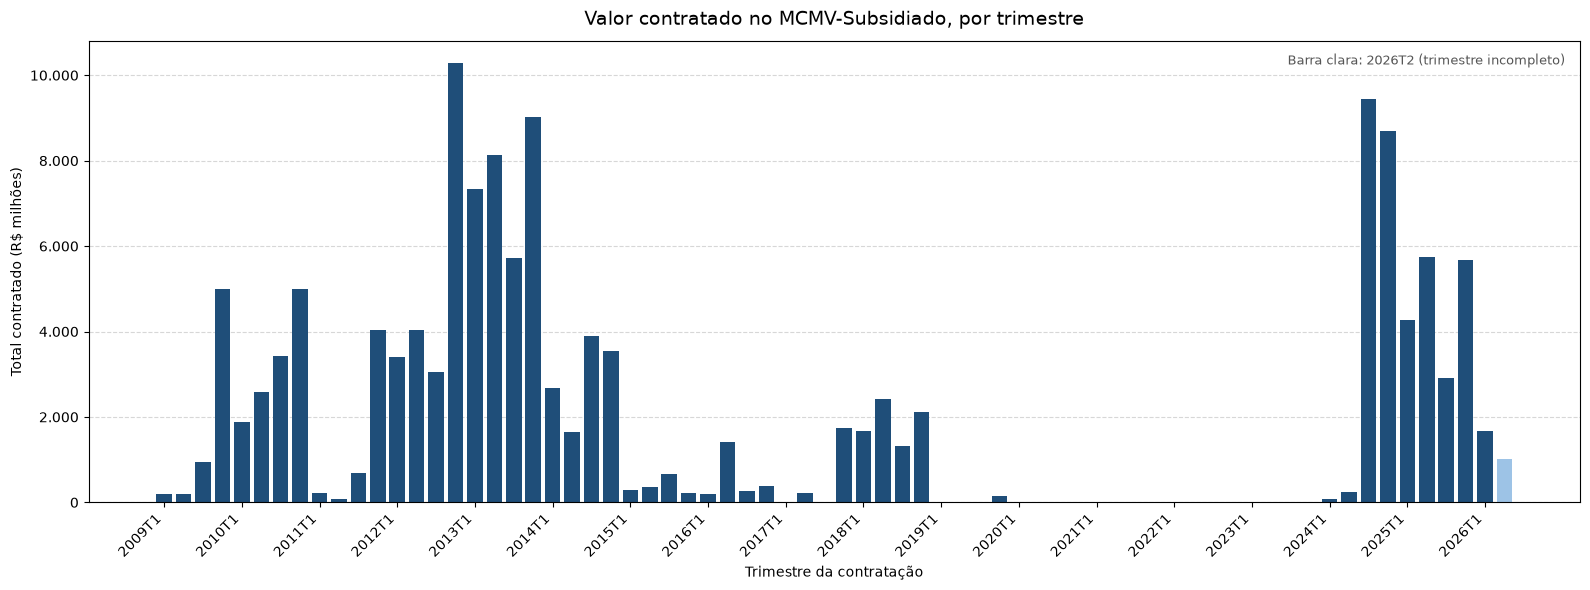

In [70]:
# Converte os trimestres (Period) em texto curto, como "2009T1", para usar como rótulos do eixo x
rotulos = [f"{p.year}T{p.quarter}" for p in serie_geral.index]

# Valores em milhões de reais, para o eixo y ficar legível
valores_mi = serie_geral.values / 1e6

# Cor única para a maioria das barras; o último trimestre (incompleto) recebe cor diferente
cores = ["#1f4e79"] * len(valores_mi)
cores[-1] = "#9dc3e6"

# Cria a figura com tamanho adequado para 70 barras
fig, ax = plt.subplots(figsize=(16, 6))

# Barras verticais: x = trimestre, y = valor em milhões
ax.bar(rotulos, valores_mi, color=cores)

# Títulos e rótulos dos eixos
ax.set_title("Valor contratado no MCMV-Subsidiado, por trimestre", fontsize=14, pad=12)
ax.set_xlabel("Trimestre da contratação")
ax.set_ylabel("Total contratado (R$ milhões)")

# Mostra apenas um rótulo a cada 4 trimestres (1 ano), para o eixo x não ficar poluído
ax.set_xticks(range(0, len(rotulos), 4))
ax.set_xticklabels(rotulos[::4], rotation=45, ha="right")

# Formata o eixo y com separador brasileiro de milhar (1.000 em vez de 1,000)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
)

# Linhas de grade horizontais, para facilitar a leitura dos valores
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

# Nota explicando a cor diferente do último trimestre
ax.text(
    0.99, 0.95, "Barra clara: 2026T2 (trimestre incompleto)",
    transform=ax.transAxes, ha="right", fontsize=9, color="#555555",
)

plt.tight_layout()
plt.show()

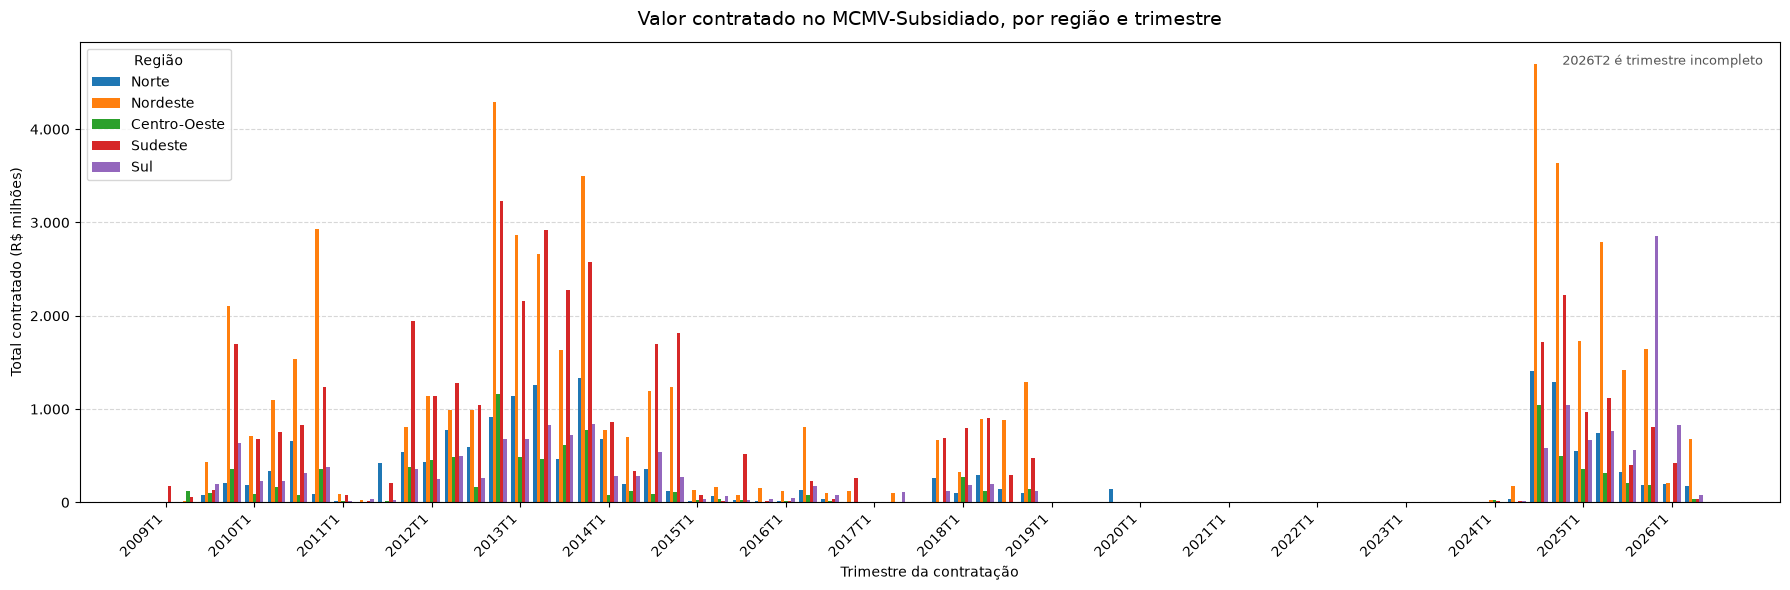

In [71]:
import numpy as np

# Rótulos do eixo x no mesmo formato do gráfico anterior (ex.: "2009T1")
rotulos = [f"{p.year}T{p.quarter}" for p in serie_regiao.index]

# Regiões em ordem fixa, para que cada cor fique sempre na mesma região
regioes = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]

# Posição central de cada trimestre no eixo x
posicoes = np.arange(len(rotulos))

# Largura de cada barra: o grupo de 5 barras ocupa cerca de 0,8 da largura do trimestre
largura = 0.8 / len(regioes)

fig, ax = plt.subplots(figsize=(18, 6))

# Uma série de barras por região, deslocada horizontalmente dentro do grupo
for i, regiao in enumerate(regioes):
    # Deslocamento: centraliza o grupo em torno da posição do trimestre
    deslocamento = (i - (len(regioes) - 1) / 2) * largura
    ax.bar(
        posicoes + deslocamento,
        serie_regiao[regiao].values / 1e6,   # valores em milhões de reais
        width=largura,
        label=regiao,
    )

ax.set_title("Valor contratado no MCMV-Subsidiado, por região e trimestre", fontsize=14, pad=12)
ax.set_xlabel("Trimestre da contratação")
ax.set_ylabel("Total contratado (R$ milhões)")

# Um rótulo de trimestre por ano, para o eixo x não ficar poluído
ax.set_xticks(posicoes[::4])
ax.set_xticklabels(rotulos[::4], rotation=45, ha="right")

# Separador brasileiro de milhar no eixo y
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
)

ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
ax.legend(title="Região")

# Mesma sinalização do gráfico anterior: o último trimestre é parcial
ax.text(
    0.99, 0.95, "2026T2 é trimestre incompleto",
    transform=ax.transAxes, ha="right", fontsize=9, color="#555555",
)

plt.tight_layout()
plt.show()

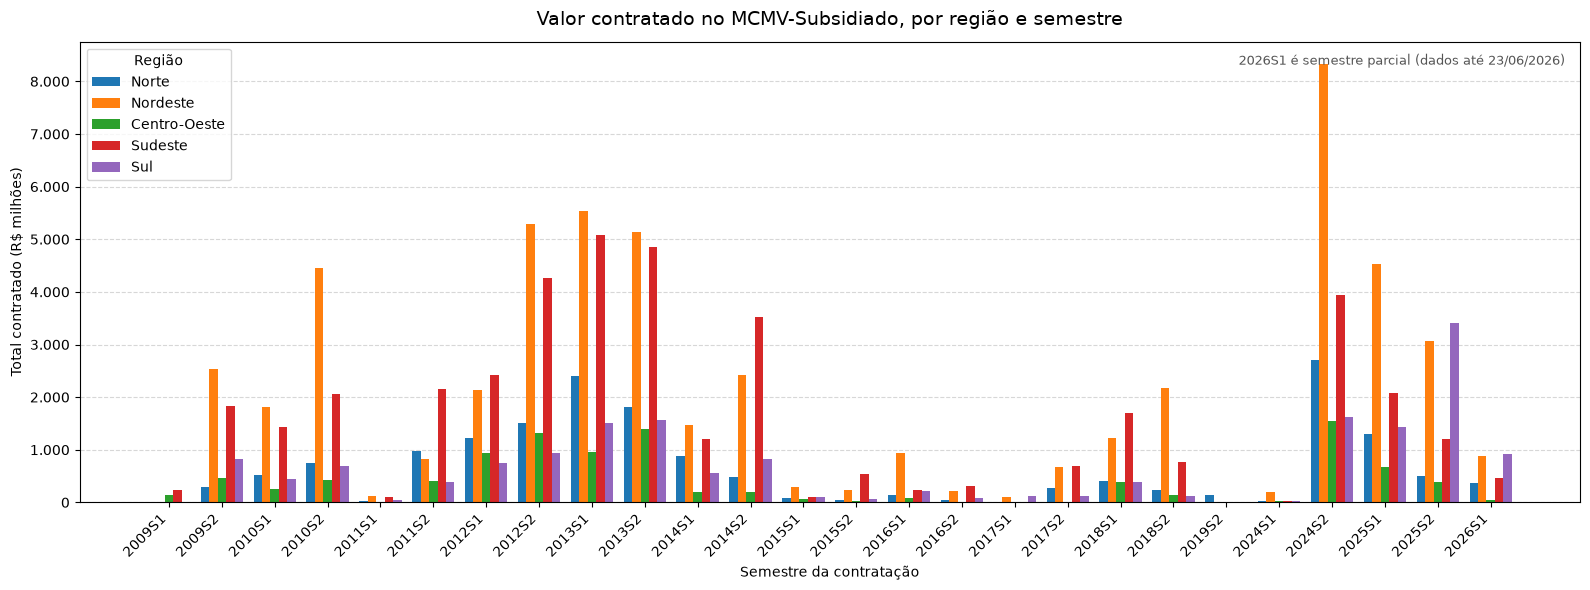

In [72]:
# Cria a coluna de semestre a partir da data de contratação.
# to_period("2Q") não existe com esse nome; por isso usamos o ano e o mês:
# meses 1 a 6 = 1º semestre, meses 7 a 12 = 2º semestre
df_sub["semestre"] = (
    df_sub["dt_assinatura"].dt.year.astype(str)
    + "S"
    + ((df_sub["dt_assinatura"].dt.month > 6) + 1).astype(str)
)

# Soma o valor contratado por semestre e região.
# unstack transforma a região em colunas, com um semestre por linha
serie_semestre_regiao = (
    df_sub.groupby(["semestre", "txt_regiao"])["val_contratado_total"]
    .sum()
    .unstack(fill_value=0)
)

# Regiões em ordem fixa, para que cada cor fique sempre na mesma região
regioes = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
serie_semestre_regiao = serie_semestre_regiao[regioes]

# Ordena os semestres cronologicamente (a ordem alfabética já funciona, pois o formato é AAAAS1/S2)
rotulos = serie_semestre_regiao.index.tolist()
posicoes = np.arange(len(rotulos))
largura = 0.8 / len(regioes)

fig, ax = plt.subplots(figsize=(16, 6))

for i, regiao in enumerate(regioes):
    deslocamento = (i - (len(regioes) - 1) / 2) * largura
    ax.bar(
        posicoes + deslocamento,
        serie_semestre_regiao[regiao].values / 1e6,
        width=largura,
        label=regiao,
    )

ax.set_title("Valor contratado no MCMV-Subsidiado, por região e semestre", fontsize=14, pad=12)
ax.set_xlabel("Semestre da contratação")
ax.set_ylabel("Total contratado (R$ milhões)")

ax.set_xticks(posicoes)
ax.set_xticklabels(rotulos, rotation=45, ha="right")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
)

ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
ax.legend(title="Região")

ax.text(
    0.99, 0.95, "2026S1 é semestre parcial (dados até 23/06/2026)",
    transform=ax.transAxes, ha="right", fontsize=9, color="#555555",
)

plt.tight_layout()
plt.show()

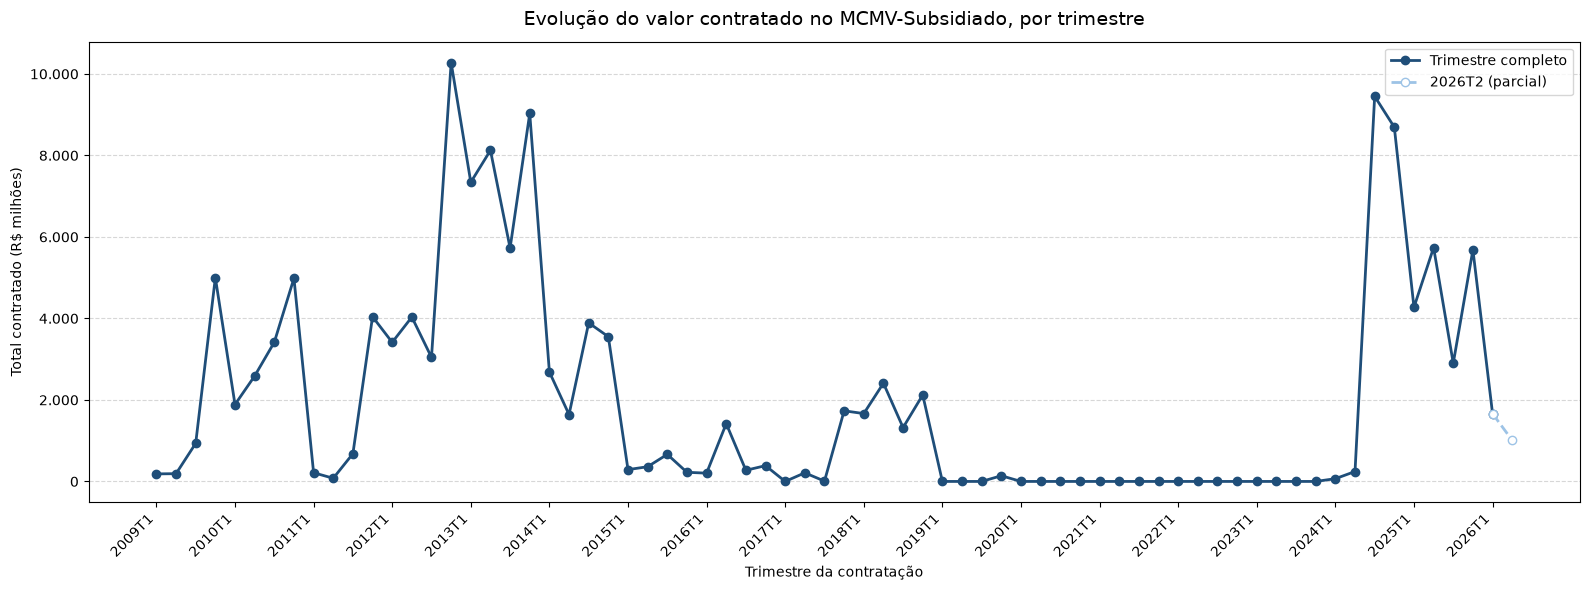

In [73]:
# Rótulos do eixo x no formato "2009T1", igual ao gráfico anterior
rotulos = [f"{p.year}T{p.quarter}" for p in serie_geral.index]

# Valores em milhões de reais para o eixo y
valores_mi = serie_geral.values / 1e6
posicoes = np.arange(len(rotulos))

fig, ax = plt.subplots(figsize=(16, 6))

# Linha principal: todos os trimestres, exceto o último (incompleto)
ax.plot(posicoes[:-1], valores_mi[:-1], marker="o", color="#1f4e79", linewidth=2, label="Trimestre completo")

# Último trimestre, desenhado separadamente com linha tracejada e marcador vazado
ax.plot(posicoes[-2:], valores_mi[-2:], linestyle="--", marker="o",
        markerfacecolor="white", color="#9dc3e6", linewidth=2, label="2026T2 (parcial)")

ax.set_title("Evolução do valor contratado no MCMV-Subsidiado, por trimestre", fontsize=14, pad=12)
ax.set_xlabel("Trimestre da contratação")
ax.set_ylabel("Total contratado (R$ milhões)")

# Um rótulo por ano (a cada 4 trimestres)
ax.set_xticks(posicoes[::4])
ax.set_xticklabels(rotulos[::4], rotation=45, ha="right")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
)

ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
ax.legend()

plt.tight_layout()
plt.show()


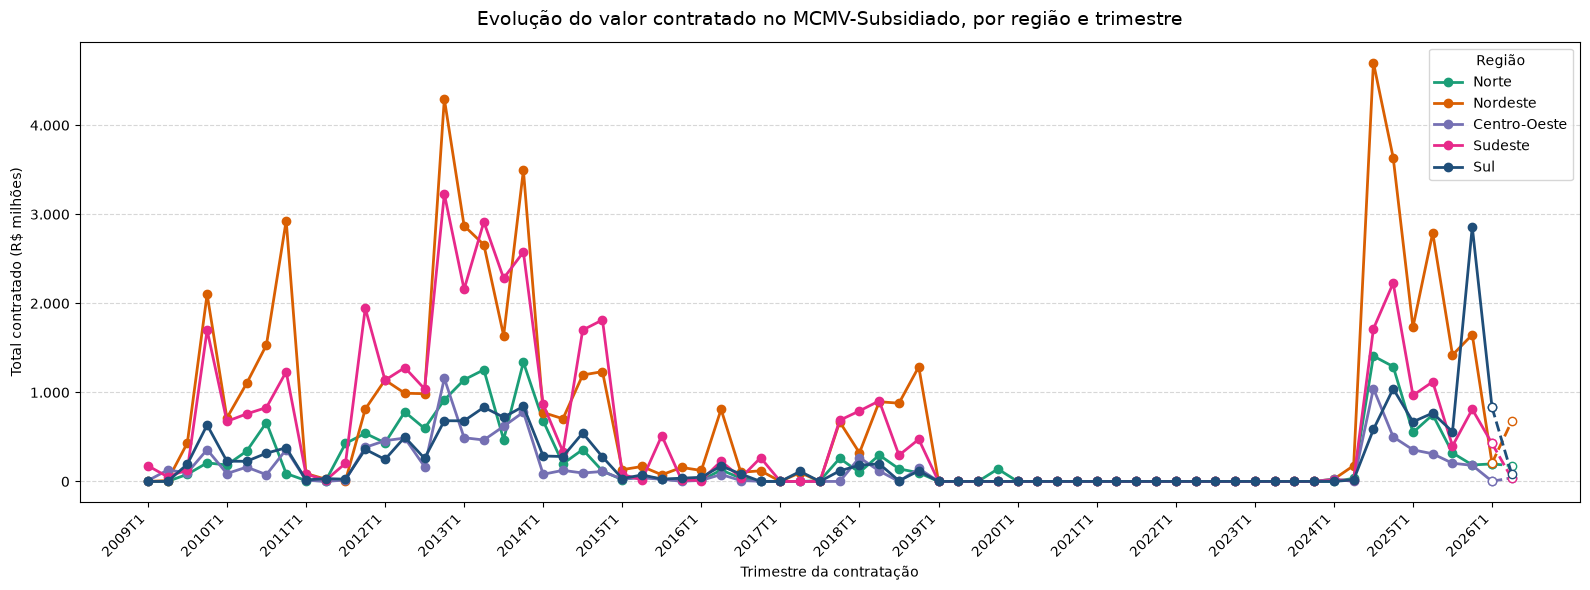

In [74]:
# Rótulos do eixo x no formato "2009T1", igual aos gráficos anteriores
rotulos = [f"{p.year}T{p.quarter}" for p in serie_regiao.index]
posicoes = np.arange(len(rotulos))

# Regiões em ordem fixa, para que cada cor fique sempre na mesma região
regioes = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]

# Paleta com uma cor distinta por região
cores = {
    "Norte": "#1b9e77",
    "Nordeste": "#d95f02",
    "Centro-Oeste": "#7570b3",
    "Sudeste": "#e7298a",
    "Sul": "#1f4e79",
}

fig, ax = plt.subplots(figsize=(16, 6))

for regiao in regioes:
    valores_mi = serie_regiao[regiao].values / 1e6

    # Linha principal: todos os trimestres, exceto o último (incompleto)
    ax.plot(
        posicoes[:-1], valores_mi[:-1],
        marker="o", linewidth=2, color=cores[regiao], label=regiao,
    )

    # Último trimestre (2026T2, parcial), com linha tracejada e marcador vazado.
    # Usa a mesma cor da região, para a legenda continuar valendo
    ax.plot(
        posicoes[-2:], valores_mi[-2:],
        linestyle="--", marker="o", markerfacecolor="white",
        linewidth=2, color=cores[regiao],
    )

ax.set_title("Evolução do valor contratado no MCMV-Subsidiado, por região e trimestre", fontsize=14, pad=12)
ax.set_xlabel("Trimestre da contratação")
ax.set_ylabel("Total contratado (R$ milhões)")

# Um rótulo por ano (a cada 4 trimestres)
ax.set_xticks(posicoes[::4])
ax.set_xticklabels(rotulos[::4], rotation=45, ha="right")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
)

ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
ax.legend(title="Região")

plt.tight_layout()
plt.show()

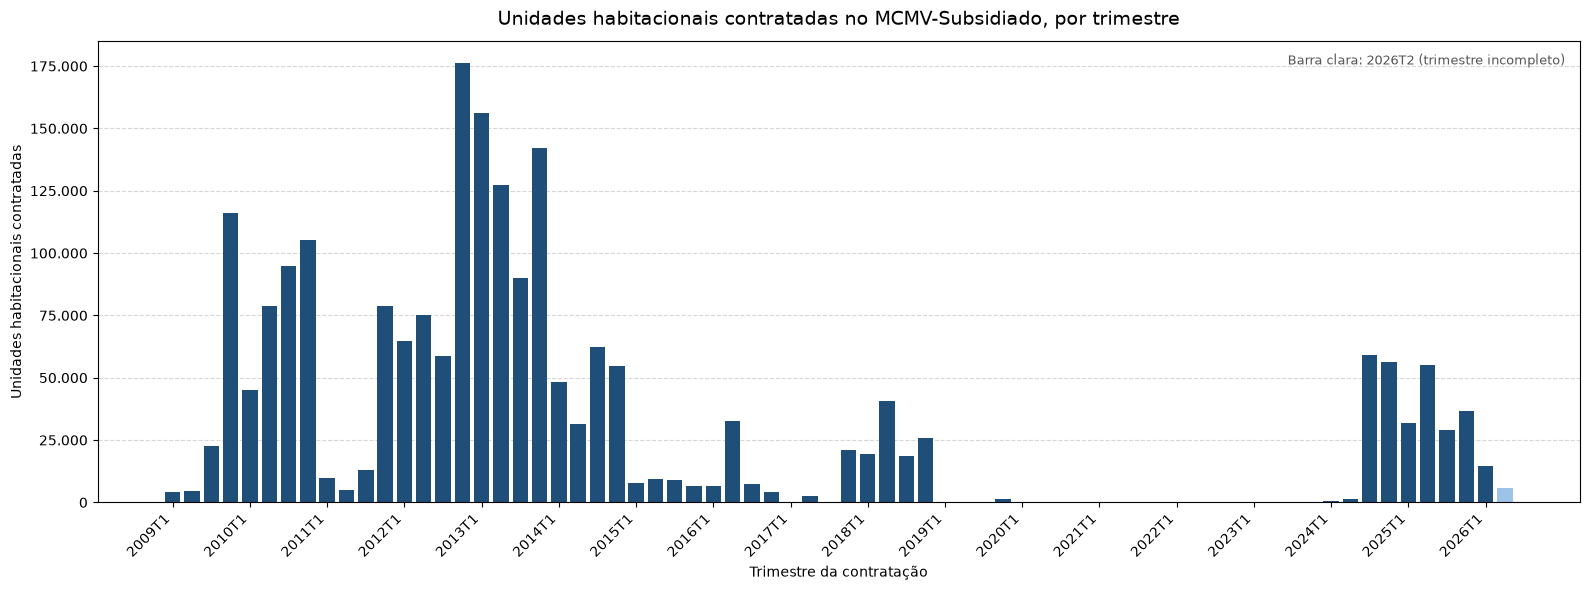

In [75]:
# Soma de unidades habitacionais contratadas por trimestre.
# Reaproveita o mesmo agrupamento da série de valores, mas com a coluna qtd_uh
serie_uh = (
    df_sub.groupby("trimestre")["qtd_uh"]
    .sum()
    .reindex(trimestres, fill_value=0)
)

# Rótulos do eixo x no formato "2009T1", igual aos gráficos anteriores
rotulos = [f"{p.year}T{p.quarter}" for p in serie_uh.index]
posicoes = np.arange(len(rotulos))

# Cor única para a maioria das barras; o último trimestre (incompleto) recebe cor diferente
cores = ["#1f4e79"] * len(rotulos)
cores[-1] = "#9dc3e6"

fig, ax = plt.subplots(figsize=(16, 6))

ax.bar(posicoes, serie_uh.values, color=cores)

ax.set_title("Unidades habitacionais contratadas no MCMV-Subsidiado, por trimestre", fontsize=14, pad=12)
ax.set_xlabel("Trimestre da contratação")
ax.set_ylabel("Unidades habitacionais contratadas")

ax.set_xticks(posicoes[::4])
ax.set_xticklabels(rotulos[::4], rotation=45, ha="right")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
)

ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

ax.text(
    0.99, 0.95, "Barra clara: 2026T2 (trimestre incompleto)",
    transform=ax.transAxes, ha="right", fontsize=9, color="#555555",
)

plt.tight_layout()
plt.show()

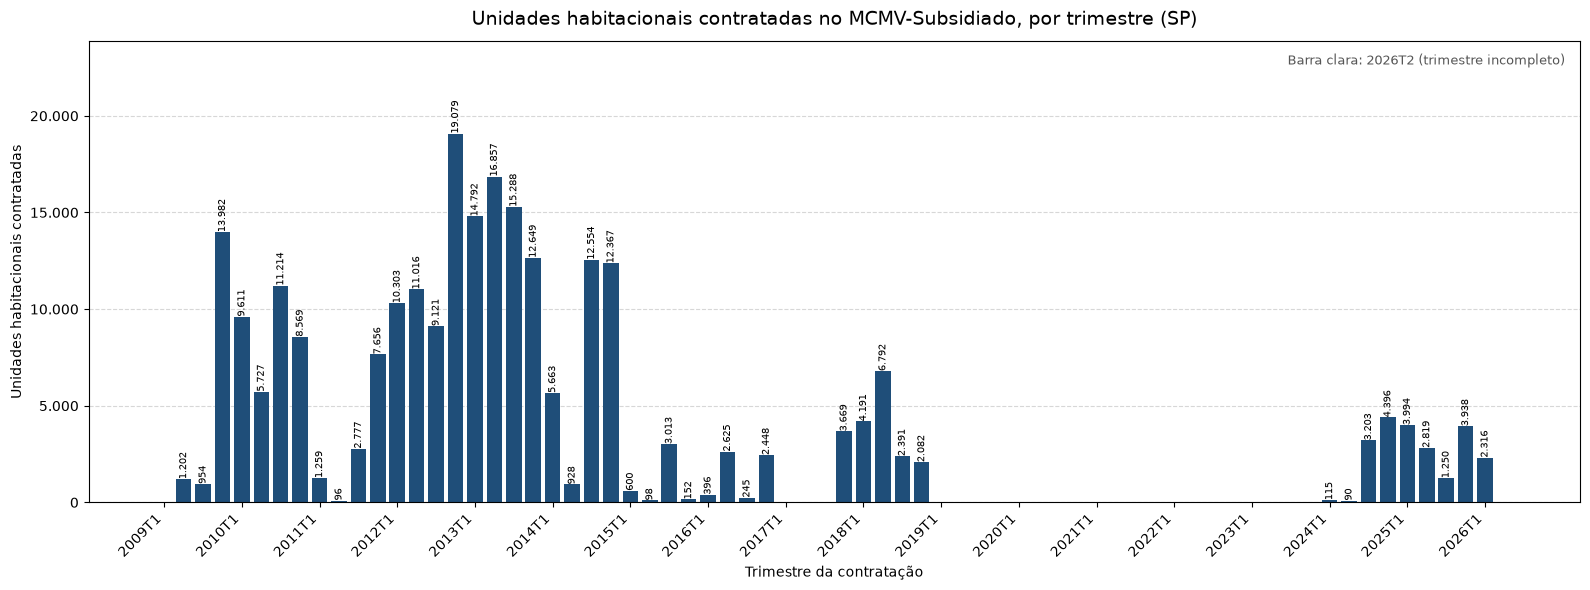

In [76]:
# Filtra só os empreendimentos localizados em São Paulo (sigla SP)
df_sp = df_sub[df_sub["txt_sigla_uf"] == "SP"]

# Soma de unidades habitacionais contratadas por trimestre, só para SP.
# reindex com os mesmos trimestres garante o eixo completo, com zero onde não houve contratação
serie_uh_sp = (
    df_sp.groupby("trimestre")["qtd_uh"]
    .sum()
    .reindex(trimestres, fill_value=0)
)

# Rótulos do eixo x no formato "2009T1", igual aos gráficos anteriores
rotulos = [f"{p.year}T{p.quarter}" for p in serie_uh_sp.index]
posicoes = np.arange(len(rotulos))

# Cor única para a maioria das barras; o último trimestre (incompleto) recebe cor diferente
cores = ["#1f4e79"] * len(rotulos)
cores[-1] = "#9dc3e6"

fig, ax = plt.subplots(figsize=(16, 6))

ax.bar(posicoes, serie_uh_sp.values, color=cores)

ax.set_title("Unidades habitacionais contratadas no MCMV-Subsidiado, por trimestre (SP)", fontsize=14, pad=12)
ax.set_xlabel("Trimestre da contratação")
ax.set_ylabel("Unidades habitacionais contratadas")

ax.set_xticks(posicoes[::4])
ax.set_xticklabels(rotulos[::4], rotation=45, ha="right")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
)

ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

ax.text(
    0.99, 0.95, "Barra clara: 2026T2 (trimestre incompleto)",
    transform=ax.transAxes, ha="right", fontsize=9, color="#555555",
)

# Acrescenta o valor no topo de cada barra, em formato de milhar brasileiro
for x, y in zip(posicoes, serie_uh_sp.values):
    if y > 0:  # evita escrever "0" nos trimestres sem contratação
        ax.text(
            x, y, f"{y:,.0f}".replace(",", "."),
            ha="center", va="bottom", rotation=90, fontsize=7,
        )

# Folga no topo para o texto não cortar
ax.set_ylim(0, serie_uh_sp.max() * 1.25)

plt.tight_layout()
plt.show()

In [77]:
# Procura os registros de São Paulo capital pelo nome, normalizando maiúsculas e acentos
mascara = df_sub["txt_nome_municipio"].str.upper().str.contains("S[ÃA]O PAULO", regex=True, na=False)
print(df_sub.loc[mascara & (df_sub["txt_sigla_uf"] == "SP"), ["cod_ibge", "txt_nome_municipio"]].drop_duplicates())

     cod_ibge txt_nome_municipio
50    355.030          São Paulo
8176  355.030         São Paulo 


In [78]:
# Filtra pelo código IBGE exibido na base (355.030), que identifica a capital de forma única
df_scidade = df_sub[df_sub["cod_ibge"] == "355.030"]

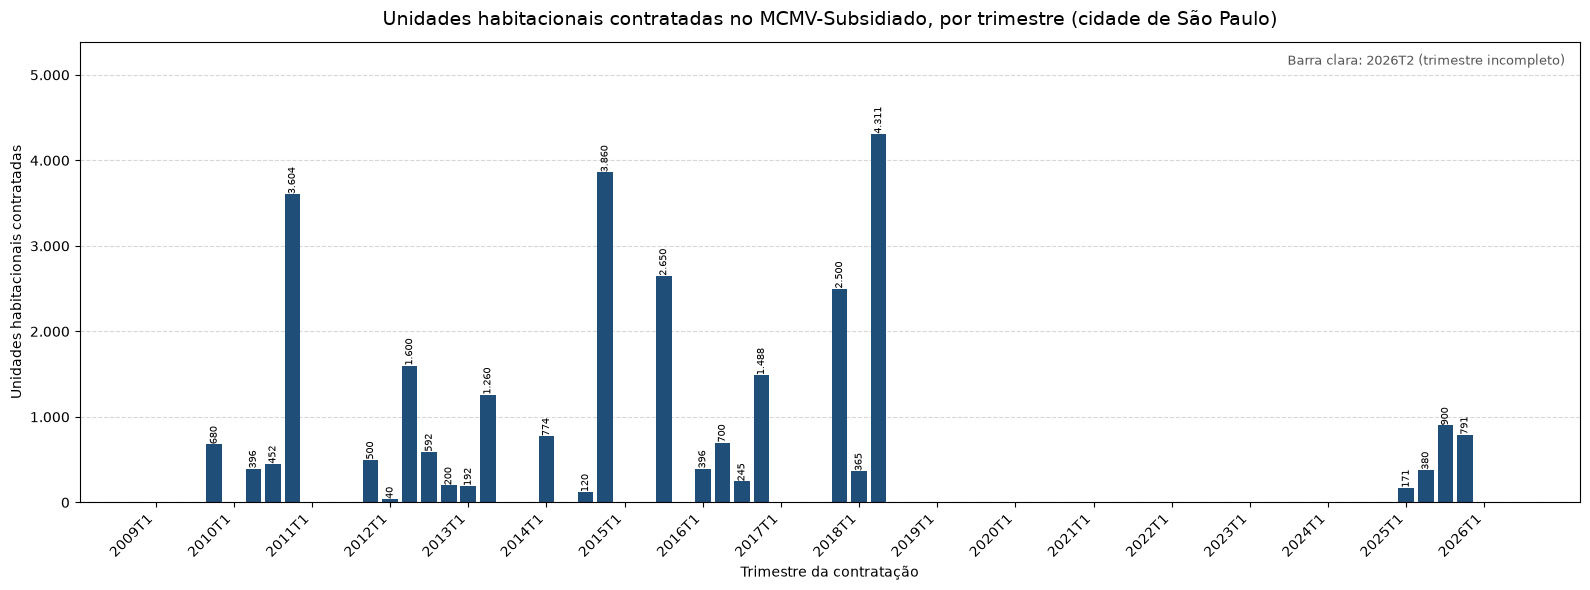

In [79]:
# Filtra os empreendimentos da cidade de São Paulo (município, não o estado)
# Ajuste o valor de cod_ibge conforme a saída da célula anterior
df_scidade = df_sub[(df_sub["txt_nome_municipio"] == "São Paulo") & (df_sub["txt_sigla_uf"] == "SP")]

# Soma de unidades habitacionais contratadas por trimestre
serie_uh_capital = (
    df_scidade.groupby("trimestre")["qtd_uh"]
    .sum()
    .reindex(trimestres, fill_value=0)
)

# Rótulos e posições no formato dos gráficos anteriores
rotulos = [f"{p.year}T{p.quarter}" for p in serie_uh_capital.index]
posicoes = np.arange(len(rotulos))

# Cor única; o último trimestre (incompleto) recebe cor diferente
cores = ["#1f4e79"] * len(rotulos)
cores[-1] = "#9dc3e6"

fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(posicoes, serie_uh_capital.values, color=cores)

ax.set_title("Unidades habitacionais contratadas no MCMV-Subsidiado, por trimestre (cidade de São Paulo)", fontsize=14, pad=12)
ax.set_xlabel("Trimestre da contratação")
ax.set_ylabel("Unidades habitacionais contratadas")

ax.set_xticks(posicoes[::4])
ax.set_xticklabels(rotulos[::4], rotation=45, ha="right")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

ax.text(
    0.99, 0.95, "Barra clara: 2026T2 (trimestre incompleto)",
    transform=ax.transAxes, ha="right", fontsize=9, color="#555555",
)

# Rótulo com o total de cada trimestre, como no gráfico de SP
for x, y in zip(posicoes, serie_uh_capital.values):
    if y > 0:
        ax.text(x, y, f"{y:,.0f}".replace(",", "."),
                ha="center", va="bottom", rotation=90, fontsize=7)

ax.set_ylim(0, serie_uh_capital.max() * 1.25)

plt.tight_layout()
plt.show()